# Explore the collected data

This notebook reads `data/warehouse.duckdb`, which is built from the raw archive. To refresh it:

1. Copy the raw archive from the VPS (over Tailscale):
   `rsync -a kac3pro@100.79.225.110:paper-trader/data/raw/ data/raw/`
2. Rebuild the warehouse: `uv run python -m paper_trader.apps.build_db`
3. Re-run the notebook from the top (the connection must be reopened to see a rebuilt file).

Use the project's `.venv` as the kernel. All times below are shown in Warsaw local time.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
con = duckdb.connect(ROOT / "data" / "warehouse.duckdb", read_only=True)
con.execute("SET TimeZone = 'Europe/Warsaw'")

## What's in the warehouse

In [2]:
con.execute("""
    SELECT 'book_snapshots' AS table_name, count(*) AS n_rows,
           min(fetched_at) AS first, max(fetched_at) AS last FROM book_snapshots
    UNION ALL SELECT 'market_status', count(*), min(fetched_at), max(fetched_at) FROM market_status
    UNION ALL SELECT 'metar_obs', count(*), min(first_seen_at), max(first_seen_at) FROM metar_obs
""").df()

/tmp/ipykernel_978426/3496960642.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  """).df()


,table_name,n_rows,first,last
0,book_snapshots,1947,2026-11-02 15:41:03.262235+01:00,2026-11-02 17:36:00.068651+01:00
1,market_status,297,2026-11-02 15:41:03.133639+01:00,2026-11-02 17:28:00.111819+01:00
2,metar_obs,14,2026-11-02 16:24:51.179582+01:00,2026-11-02 17:08:08.979237+01:00


In [3]:
con.execute("""
    SELECT target_date, title, first_seen_at, last_seen_at,
           (SELECT count(*) FROM brackets b WHERE b.event_id = e.event_id) AS n_brackets
    FROM events e
    ORDER BY target_date
""").df()

/tmp/ipykernel_978426/2927487446.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  """).df()


,target_date,title,first_seen_at,last_seen_at,n_brackets
0,2026-11-02,Highest temperature in Warsaw on November 2?,2026-11-02 15:41:03.133639+01:00,2026-11-02 17:28:00.063793+01:00,11
1,2026-11-03,Highest temperature in Warsaw on November 3?,2026-11-02 15:41:03.158770+01:00,2026-11-02 17:28:00.086075+01:00,11
2,2026-11-04,Highest temperature in Warsaw on November 4?,2026-11-02 15:41:03.182265+01:00,2026-11-02 17:28:00.111819+01:00,11


## Market-implied distribution (latest poll)

Mid prices normalized to sum to 1 across each event's brackets.

,target_date,label,lo_c,bid,ask,mid,implied_prob
0,2026-11-02,8°C,8,0.994,0.999,0.9965,0.996002
1,2026-11-02,9°C,9,0.002,0.006,0.0040,0.003998
2,2026-11-03,4°C,4,0.001,0.002,0.0015,0.001463
3,2026-11-03,5°C,5,0.001,0.003,0.0020,0.001951
4,2026-11-03,6°C,6,0.002,0.004,0.0030,0.002927
5,2026-11-03,7°C,7,0.011,0.023,0.0170,0.016585
6,2026-11-03,8°C,8,0.170,0.210,0.1900,0.185366
7,2026-11-03,9°C,9,0.510,0.540,0.5250,0.512195
8,2026-11-03,10°C,10,0.250,0.280,0.2650,0.258537
9,2026-11-03,11°C,11,0.016,0.024,0.0200,0.019512


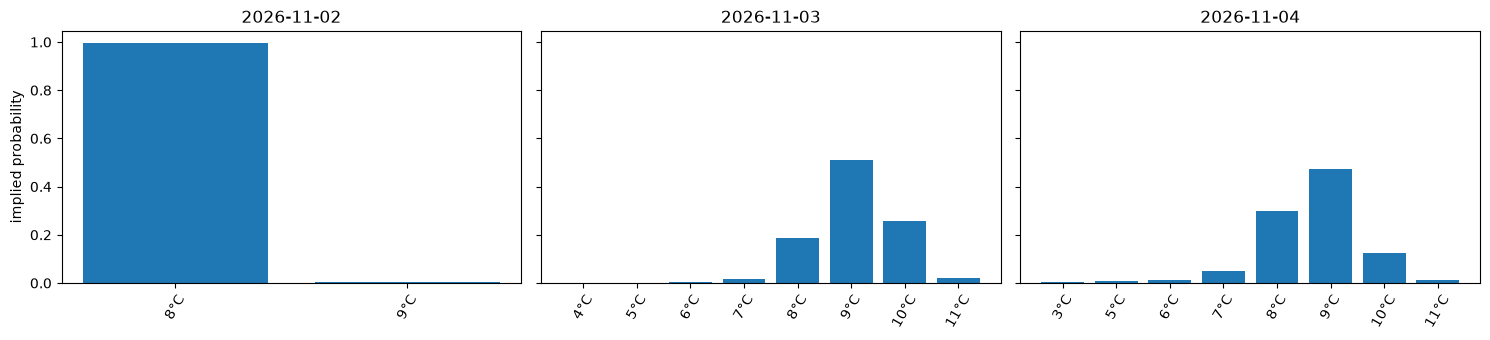

In [4]:
latest = con.execute("""
    SELECT target_date::VARCHAR AS target_date, label, lo_c,
           best_bid::DOUBLE AS bid, best_ask::DOUBLE AS ask,
           mid::DOUBLE AS mid, implied_prob
    FROM market_implied JOIN book_top USING (fetched_at, target_date, label, lo_c, hi_c, mid)
    WHERE fetched_at = (SELECT max(fetched_at) FROM market_implied)
    ORDER BY target_date, lo_c NULLS FIRST
""").df()

dates = sorted(latest["target_date"].unique())
fig, axes = plt.subplots(1, len(dates), figsize=(5 * len(dates), 3.5), sharey=True, squeeze=False)
for ax, d in zip(axes[0], dates, strict=True):
    day = latest[latest["target_date"] == d]
    ax.bar(day["label"], day["implied_prob"])
    ax.set_title(str(d))
    ax.tick_params(axis="x", rotation=60)
axes[0][0].set_ylabel("implied probability")
fig.tight_layout()
latest

## Price history of one event

Mid price of each bracket over time. Pick any `target_date` from the table above.

/tmp/ipykernel_978426/3521971863.py:11: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ).df()


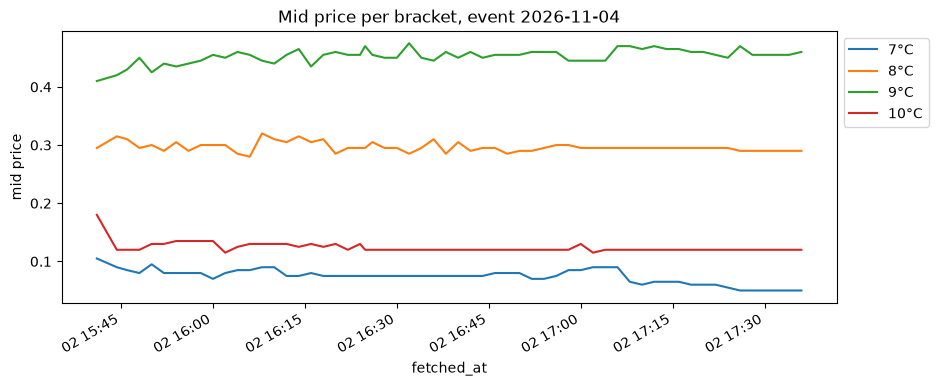

In [5]:
TARGET = max(dates)  # the furthest-out event; or any date, e.g. "2026-11-03"

history = con.execute(
    """
    SELECT fetched_at, label, lo_c, mid::DOUBLE AS mid
    FROM book_top
    WHERE target_date = ?
    ORDER BY fetched_at
""",
    [TARGET],
).df()

wide = history.pivot_table(index="fetched_at", columns="label", values="mid")
order = history.drop_duplicates("label").sort_values("lo_c", na_position="first")["label"]
wide = wide[[c for c in order if c in wide and wide[c].max() >= 0.02]]  # only relevant ones

ax = wide.plot(figsize=(10, 4), title=f"Mid price per bracket, event {TARGET}")
ax.set_ylabel("mid price")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

## Order book depth of the favourite bracket (latest poll)

In [6]:
depth = con.execute(
    """
    WITH fav AS (
        SELECT * FROM market_implied
        WHERE target_date = ? AND fetched_at = (SELECT max(fetched_at) FROM market_implied)
        ORDER BY implied_prob DESC LIMIT 1
    ), snap AS (
        SELECT s.* FROM book_snapshots s
        JOIN brackets b ON b.yes_token_id = s.token_id
        JOIN events e ON e.event_id = b.event_id
        JOIN fav ON fav.label = b.label AND fav.target_date = e.target_date
                AND fav.fetched_at = s.fetched_at
    )
    SELECT 'bid' AS side, l.price::DOUBLE AS price, l.size::DOUBLE AS size
    FROM snap, unnest(snap.bids) AS t(l)
    UNION ALL
    SELECT 'ask', l.price::DOUBLE, l.size::DOUBLE
    FROM snap, unnest(snap.asks) AS t(l)
    ORDER BY price DESC
""",
    [TARGET],
).df()
depth[(depth["price"] > 0.05) & (depth["price"] < 0.95)]

,side,price,size
5,ask,0.94,16.66
6,ask,0.92,12.50
7,ask,0.91,478.00
8,ask,0.90,10.00
9,ask,0.88,8.33
10,ask,0.86,7.14
11,ask,0.84,6.25
12,ask,0.82,5.55
13,ask,0.80,5.00
14,ask,0.79,40.00


## METAR temperatures at EPWA

Each distinct report, with the time it was observed. `metar_daily` is a *preliminary* daily
max (routine reports only, latest version of each); the real resolution logic comes later.

/tmp/ipykernel_978426/390837014.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  """).df()
/tmp/ipykernel_978426/390837014.py:18: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  con.execute("SELECT * FROM metar_daily ORDER BY local_date").df()


,station,local_date,max_temp_c,n_reports,first_obs,last_obs
0,EPWA,2026-11-02,8,14,2026-11-02 10:30:00+01:00,2026-11-02 17:00:00+01:00


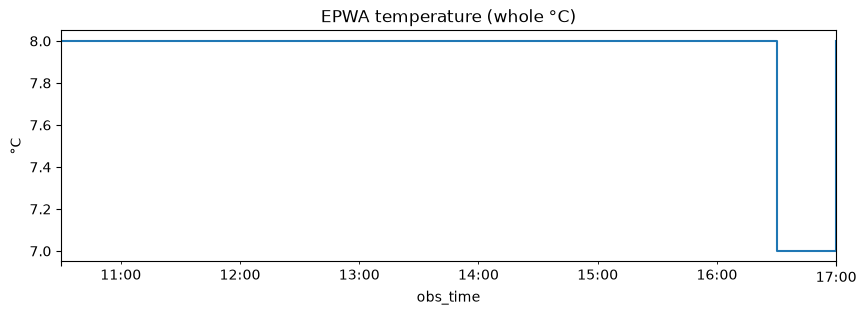

In [7]:
obs = con.execute("""
    SELECT obs_time, report_type, temp_body_c, is_correction, raw
    FROM metar_obs
    ORDER BY obs_time
""").df()

routine = obs[obs["report_type"] != "SPECI"]
ax = routine.plot(
    x="obs_time",
    y="temp_body_c",
    drawstyle="steps-post",
    figsize=(10, 3),
    legend=False,
    title="EPWA temperature (whole °C)",
)
ax.set_ylabel("°C")

con.execute("SELECT * FROM metar_daily ORDER BY local_date").df()